![OpenTelemetry in Depth](assets/banner-adv-02.svg)

OpenTelemetry (OTel) is the open standard for producing and shipping telemetry. It is a CNCF project supported by every major observability vendor, which means code instrumented with OTel can send data to Langfuse, LangSmith, Datadog, Dynatrace, Grafana and others **without changing a line of application code**.

This notebook builds the pipeline piece by piece so nothing about it is magic.

## The moving parts

![OTel pipeline](assets/otel-pipeline.svg)

| Piece | Responsibility | Analogy |
|---|---|---|
| **API** | `trace.get_tracer()`, `start_as_current_span()`. What libraries call. Does nothing on its own. | The plug socket |
| **SDK** | The real implementation: `TracerProvider`, sampling, IDs, timing | The wiring behind the wall |
| **Resource** | Who is emitting: `service.name`, version, environment | The return address on a parcel |
| **SpanProcessor** | When to hand finished spans on: immediately or in batches | The mailroom |
| **Exporter** | How and where to send: OTLP/HTTP, OTLP/gRPC, console | The courier |
| **Collector** | Optional separate process that receives, filters, redacts and routes | The sorting hub |
| **Semantic conventions** | Agreed attribute names such as `gen_ai.request.model` | The address format everyone agrees on |

The API/SDK split matters: libraries like OpenAI instrumentations depend only on the API, so they cost nothing until *your* application installs an SDK and decides where data goes.

## 1. The smallest working setup

A provider with a resource, a processor, and an exporter that prints to the notebook.

In [1]:
from opentelemetry.sdk.resources import Resource
from opentelemetry.sdk.trace import TracerProvider
from opentelemetry.sdk.trace.export import ConsoleSpanExporter, SimpleSpanProcessor

resource = Resource.create(
    {"service.name": "weather-agent", "service.version": "1.4.0", "deployment.environment": "dev"}
)
provider = TracerProvider(resource=resource)
provider.add_span_processor(SimpleSpanProcessor(ConsoleSpanExporter()))
tracer = provider.get_tracer("notebook.02")

with tracer.start_as_current_span("hello-span") as span:
    span.set_attribute("greeting", "hi")

{
    "name": "hello-span",
    "context": {
        "trace_id": "0x4262b6c536fe9aba2a1246a73b9fa155",
        "span_id": "0x2b5bd9117cbad817",
        "trace_state": "[]"
    },
    "kind": "SpanKind.INTERNAL",
    "parent_id": null,
    "start_time": "2026-10-21T00:55:10.872377Z",
    "end_time": "2026-10-21T00:55:10.872449Z",
    "status": {
        "status_code": "UNSET"
    },
    "attributes": {
        "greeting": "hi"
    },
    "events": [],
    "links": [],
    "resource": {
        "attributes": {
            "telemetry.sdk.language": "python",
            "telemetry.sdk.name": "opentelemetry",
            "telemetry.sdk.version": "1.45.1",
            "service.instance.id": "56b55e89-762c-4eb9-b576-b29c41f4471e",
            "service.name": "weather-agent",
            "service.version": "1.4.0",
            "deployment.environment": "dev"
        },
        "schema_url": ""
    }
}


Notice three things in that JSON:
- `context.trace_id` and `span_id` are random 128 bit and 64 bit identifiers generated by the SDK.
- `parent_id` is `null`: this span is a **root**.
- `resource` is attached to every span automatically, so the backend knows which service sent it.

## 2. Everything a span can carry

| Field | Use it for | Example |
|---|---|---|
| **name** | Low-cardinality operation name | `chat gpt-4o-mini`, not `chat for user 42` |
| **kind** | Role in a call: `INTERNAL`, `CLIENT`, `SERVER`, `PRODUCER`, `CONSUMER` | An LLM API call is `CLIENT` |
| **attributes** | Key/value facts about the operation | `gen_ai.usage.input_tokens=640` |
| **events** | Timestamped moments inside the span | `retry`, `first_token` |
| **status** | `UNSET`, `OK` or `ERROR` | Error when the tool times out |
| **links** | Pointers to related spans in other traces | A batch job linking to the requests it serves |

In [2]:
import time

from opentelemetry.sdk.trace.export.in_memory_span_exporter import InMemorySpanExporter
from opentelemetry.trace import SpanKind, Status, StatusCode

memory = InMemorySpanExporter()
provider = TracerProvider(resource=resource)
provider.add_span_processor(SimpleSpanProcessor(memory))
tracer = provider.get_tracer("notebook.02")

with tracer.start_as_current_span("chat gpt-4o-mini", kind=SpanKind.CLIENT) as span:
    span.set_attribute("gen_ai.operation.name", "chat")
    span.set_attribute("gen_ai.request.model", "gpt-4o-mini")
    time.sleep(0.05)
    span.add_event("gen_ai.first_token", {"elapsed_ms": 50})
    time.sleep(0.10)
    try:
        raise TimeoutError("upstream took longer than 30s")
    except TimeoutError as exc:
        span.record_exception(exc)
        span.set_status(Status(StatusCode.ERROR, "timeout"))
        span.set_attribute("error.type", "TimeoutError")

s = memory.get_finished_spans()[0]
print("kind      ", s.kind.name)
print("status    ", s.status.status_code.name, "|", s.status.description)
print("attributes", dict(s.attributes))
for e in s.events:
    print("event     ", e.name, dict(e.attributes) if e.name != "exception" else e.attributes["exception.type"])

kind       CLIENT
status     ERROR | timeout
attributes {'gen_ai.operation.name': 'chat', 'gen_ai.request.model': 'gpt-4o-mini', 'error.type': 'TimeoutError'}
event      gen_ai.first_token {'elapsed_ms': 50}
event      exception TimeoutError


`record_exception` stores the exception type, message and stack trace as an event, so a backend can show *where* it failed, not just *that* it failed.

## 3. How spans find their parent

OTel keeps the **current span** in a context variable. Starting a span inside another one makes it a child automatically, even across function calls. No IDs are passed around by hand.

In [3]:
memory.clear()


def fetch_weather():
    with tracer.start_as_current_span("execute_tool get_weather"):
        time.sleep(0.02)


def agent():
    with tracer.start_as_current_span("invoke_agent weather-agent"):
        fetch_weather()


agent()
for s in memory.get_finished_spans():
    parent = f"{s.parent.span_id:016x}" if s.parent else "none (root)"
    print(f"{s.name:28} span={s.context.span_id:016x}  parent={parent}  trace={s.context.trace_id:032x}")

execute_tool get_weather     span=16accdc934c6d397  parent=b5b98277d3aeb233  trace=cea415f1b2a8fd1cf8cc4e5085824e2c
invoke_agent weather-agent   span=b5b98277d3aeb233  parent=none (root)  trace=cea415f1b2a8fd1cf8cc4e5085824e2c


## 4. Crossing a network boundary

Inside one process, context lives in memory. Between services it travels in an HTTP header called **`traceparent`** (the W3C Trace Context standard). The caller *injects* it; the callee *extracts* it and continues the same trace.

Below, an "agent service" calls a separate "weather service". We pass a plain `dict` as the HTTP headers.

In [4]:
from opentelemetry.trace.propagation.tracecontext import TraceContextTextMapPropagator

propagator = TraceContextTextMapPropagator()
memory.clear()


def weather_service(headers: dict):
    """Runs in a different service. Its only link to the caller is the header."""
    ctx = propagator.extract(headers)
    with tracer.start_as_current_span("GET /weather", context=ctx, kind=SpanKind.SERVER):
        time.sleep(0.03)


with tracer.start_as_current_span("invoke_agent weather-agent"):
    with tracer.start_as_current_span("HTTP GET weather-service", kind=SpanKind.CLIENT):
        headers = {}
        propagator.inject(headers)
        weather_service(headers)

print("header sent:", headers["traceparent"], "\n")
version, trace_id, parent_id, flags = headers["traceparent"].split("-")
sampled = int(flags, 16) & 0x01
print(f"  version  {version}\n  trace-id {trace_id}\n  parent   {parent_id}\n  flags    {flags} (sampled bit = {sampled})\n")
for s in memory.get_finished_spans():
    print(f"{s.name:28} {s.kind.name:7} trace={s.context.trace_id:032x}")

header sent: 00-83b7b8cbc4d7c04536c83c7f1b9f0428-a3b30cde83ebde33-03 

  version  00
  trace-id 83b7b8cbc4d7c04536c83c7f1b9f0428
  parent   a3b30cde83ebde33
  flags    03 (sampled bit = 1)

GET /weather                 SERVER  trace=83b7b8cbc4d7c04536c83c7f1b9f0428
HTTP GET weather-service     CLIENT  trace=83b7b8cbc4d7c04536c83c7f1b9f0428
invoke_agent weather-agent   INTERNAL trace=83b7b8cbc4d7c04536c83c7f1b9f0428


All three spans share one `trace_id`, so the backend draws one tree spanning two services. This is how a trace can follow a request from a web frontend, through an API, into an agent and out to tool microservices.

## 5. Simple vs batch processing, and why `flush()` matters

`SimpleSpanProcessor` exports every span the moment it ends: easy to reason about, but it adds a network call to your request path. `BatchSpanProcessor` buffers spans and exports them from a background thread. Production code should use batching, which has one consequence worth seeing.

In [5]:
from opentelemetry.sdk.trace.export import BatchSpanProcessor

batch_memory = InMemorySpanExporter()
batch_provider = TracerProvider(resource=resource)
batch_provider.add_span_processor(BatchSpanProcessor(batch_memory, schedule_delay_millis=60_000))
batch_tracer = batch_provider.get_tracer("notebook.02")

for i in range(5):
    with batch_tracer.start_as_current_span(f"request-{i}"):
        pass

print("exported before flush:", len(batch_memory.get_finished_spans()))
batch_provider.force_flush()
print("exported after flush: ", len(batch_memory.get_finished_spans()))

exported before flush: 0
exported after flush:  5


> **Lesson.** In a long-running server the batch flushes on a timer. In a script, a notebook, a serverless function or a CLI, the process may exit before that timer fires, and the spans are silently lost. Always call `force_flush()` (or the SDK's `flush()`) before a short-lived process ends.

## 6. Sampling

At high traffic you may not want every trace. A **sampler** decides at the root span whether a trace is recorded; children inherit the decision so traces are never half-recorded.

In [6]:
from opentelemetry.sdk.trace.sampling import ParentBased, TraceIdRatioBased

sampled_memory = InMemorySpanExporter()
sampled_provider = TracerProvider(resource=resource, sampler=ParentBased(TraceIdRatioBased(0.25)))
sampled_provider.add_span_processor(SimpleSpanProcessor(sampled_memory))
sampled_tracer = sampled_provider.get_tracer("notebook.02")

for i in range(400):
    with sampled_tracer.start_as_current_span("request"):
        with sampled_tracer.start_as_current_span("child"):
            pass

kept = {s.context.trace_id for s in sampled_memory.get_finished_spans()}
print(f"400 traces started, {len(kept)} kept ({len(kept) / 4:.0f}%), each with both spans intact")

400 traces started, 85 kept (21%), each with both spans intact


For LLM apps, head sampling like this is a trade-off: the trace you need to debug may be one you dropped. Many teams keep 100% of LLM traces (volume is lower than web traffic) and sample only noisy internal spans, or use tail sampling in the Collector to keep all errors and slow traces.

## 7. GenAI semantic conventions

Semantic conventions are the shared vocabulary that lets any backend understand your spans. The GenAI conventions define how to describe model calls, tools and agents. They are still marked **Development** and moved to their own repository (`open-telemetry/semantic-conventions-genai`) in 2026, so expect occasional renames.

| Operation (`gen_ai.operation.name`) | Span name | Used for |
|---|---|---|
| `chat` | `chat {model}` | Chat completion calls |
| `embeddings` | `embeddings {model}` | Embedding calls |
| `retrieval` | `retrieval {data_source}` | Vector store or search lookups |
| `execute_tool` | `execute_tool {tool_name}` | Running a tool the model chose |
| `invoke_agent` | `invoke_agent {agent_name}` | One agent run |
| `create_agent` | `create_agent {agent_name}` | Agent setup |

| Attribute | Meaning |
|---|---|
| `gen_ai.provider.name` | `openai`, `anthropic`, `aws.bedrock`, ... |
| `gen_ai.request.model` / `gen_ai.response.model` | Model asked for vs model that answered |
| `gen_ai.usage.input_tokens` / `output_tokens` | Token usage, the basis of cost |
| `gen_ai.response.finish_reasons` | `stop`, `length`, `tool_calls`, `content_filter` |
| `gen_ai.request.temperature`, `max_tokens` | Request parameters |
| `gen_ai.tool.name`, `gen_ai.agent.name` | Which tool or agent |
| `error.type` | Error class when the operation failed |

Prompt and completion **content** is opt-in in the conventions because it can contain personal data.

## 8. Ship real GenAI spans to Langfuse over OTLP

Now the payoff. We instrument the weather agent with plain OpenTelemetry and conventions only, no Langfuse SDK, and export with OTLP/HTTP to the local Langfuse. Then we ask Langfuse what it understood.

In [7]:
import base64
import os

from opentelemetry.exporter.otlp.proto.http.trace_exporter import OTLPSpanExporter

import lab  # loads ../.env

auth = base64.b64encode(f"{os.environ['LANGFUSE_PUBLIC_KEY']}:{os.environ['LANGFUSE_SECRET_KEY']}".encode()).decode()
otlp = OTLPSpanExporter(
    endpoint=f"{os.environ['LANGFUSE_BASE_URL']}/api/public/otel/v1/traces",
    headers={"Authorization": f"Basic {auth}", "x-langfuse-ingestion-version": "4"},
)
otel_provider = TracerProvider(resource=Resource.create({"service.name": "weather-agent-otel"}))
otel_provider.add_span_processor(BatchSpanProcessor(otlp))
otel_tracer = otel_provider.get_tracer("weather-agent")

In [8]:
from openai import OpenAI

client = OpenAI()
MODEL = "gpt-4o-mini"


def answer_question(question: str, city: str) -> str:
    with otel_tracer.start_as_current_span("invoke_agent weather-agent") as root:
        root.set_attribute("gen_ai.operation.name", "invoke_agent")
        root.set_attribute("gen_ai.agent.name", "weather-agent")
        root.set_attribute("user.id", "notebook-02")

        with otel_tracer.start_as_current_span("retrieval docs") as span:
            span.set_attribute("gen_ai.operation.name", "retrieval")
            docs = lab.search_docs_impl(question)

        with otel_tracer.start_as_current_span("execute_tool get_weather") as span:
            span.set_attribute("gen_ai.operation.name", "execute_tool")
            span.set_attribute("gen_ai.tool.name", "get_weather")
            weather = lab.get_weather_impl(city, flaky=False)

        with otel_tracer.start_as_current_span(f"chat {MODEL}", kind=SpanKind.CLIENT) as span:
            span.set_attribute("gen_ai.operation.name", "chat")
            span.set_attribute("gen_ai.provider.name", "openai")
            span.set_attribute("gen_ai.request.model", MODEL)
            span.set_attribute("gen_ai.request.max_tokens", 80)
            resp = client.chat.completions.create(
                model=MODEL, messages=lab.build_messages(question, docs, weather), max_tokens=80
            )
            span.set_attribute("gen_ai.response.model", resp.model)
            span.set_attribute("gen_ai.usage.input_tokens", resp.usage.prompt_tokens)
            span.set_attribute("gen_ai.usage.output_tokens", resp.usage.completion_tokens)
            span.set_attribute("gen_ai.response.finish_reasons", [c.finish_reason for c in resp.choices])
        return resp.choices[0].message.content


for city in ["Paris", "Tokyo", "London"]:
    print(f"{city:7}", answer_question(f"Should I carry an umbrella in {city}?", city))

otel_provider.force_flush();

Paris   Yes, you should carry an umbrella in Paris since the chance of rain is 70%.


Tokyo   No, you should not carry an umbrella in Tokyo since the chance of rain is only 20%.


London  Yes, you should carry an umbrella in London since the chance of rain is 85%.


Langfuse reads the GenAI attributes and maps each span to one of its own observation types. It also looks up the model's price and computes cost, even though we never sent a dollar figure.

In [9]:
time.sleep(3)
roots = lab.langfuse_observations(limit=10, userId="notebook-02")  # user.id was set on the root span
last_trace = roots.sort_values("startTime")["traceId"].iloc[-1]
obs = lab.langfuse_observations(traceId=last_trace)
latest = obs.sort_values(["startTime", "latency"], ascending=[True, False])
view = latest.assign(
    tokens=latest["usageDetails"].map(lambda u: (u or {}).get("total")),
    cost_usd=latest["totalCost"],
)[["name", "type", "tokens", "cost_usd", "latency"]]
view.style.format({"cost_usd": "{:.6f}", "latency": "{:.2f}s", "tokens": "{:.0f}"}, na_rep="").hide(axis="index")

name,type,tokens,cost_usd,latency
invoke_agent weather-agent,agent,,,1.20s
retrieval docs,span,,,0.22s
get_weather,tool,,,0.35s
chat gpt-4o-mini,generation,97,0.000023,0.63s


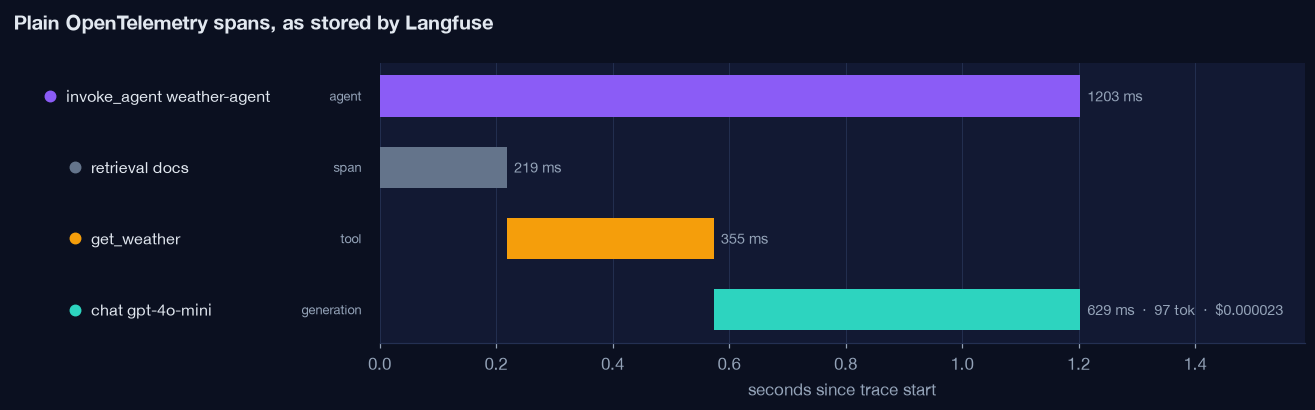

In [10]:
lab.show_trace(last_trace, "Plain OpenTelemetry spans, as stored by Langfuse");

| Our span (`gen_ai.operation.name`) | Langfuse observation type |
|---|---|
| `invoke_agent` | `AGENT` |
| `execute_tool` | `TOOL` |
| `chat` | `GENERATION` (with model, tokens and cost) |
| `retrieval` | `SPAN` (generic) |

Open **http://localhost:3000** and filter traces by user `notebook-02` to see the same trees in the UI.

## 9. Switching backends is configuration

Every OTLP exporter also reads standard environment variables. The application code above would not change at all:

```bash
# Langfuse (self-hosted or cloud)
OTEL_EXPORTER_OTLP_ENDPOINT=http://localhost:3000/api/public/otel
OTEL_EXPORTER_OTLP_HEADERS=Authorization=Basic%20<base64 pk:sk>,x-langfuse-ingestion-version=4

# LangSmith
OTEL_EXPORTER_OTLP_ENDPOINT=https://api.smith.langchain.com/otel
OTEL_EXPORTER_OTLP_HEADERS=x-api-key=<key>,Langsmith-Project=<project>

# An OpenTelemetry Collector that fans out to several vendors
OTEL_EXPORTER_OTLP_ENDPOINT=http://collector:4318
```

## Takeaways

- The **API** is what code calls; the **SDK** decides sampling, batching and destination.
- Context propagation, in process and via `traceparent`, is what turns separate spans into one trace.
- Use **batch** processing in production and **flush** in short-lived processes.
- **GenAI semantic conventions** make your spans portable: Langfuse understood ours with zero vendor code.

Next: [03 Langfuse](03_langfuse_in_depth.ipynb), where the vendor SDK adds sessions, users, scores and prompt tracking on top of this foundation.